# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ayazahmedbscsf23-art/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

In [21]:

# Section 1: Research Question

research_question = (
    "Can a machine-learning approach prioritize search pages for "
    "human review more effectively than a simple rule-based baseline "
    "using available search-performance data?"
)

project_goal = (
    "Investigate whether a data-driven approach can help content teams "
    "identify which search pages deserve attention first."
)

success_criteria = [
    "Identify the dataset and define the prediction or ranking target.",
    "Establish a simple, explainable baseline.",
    "Evaluate both approaches on the same held-out data.",
    "Compare appropriate metrics and report the actual results.",
    "Make recommendations supported by the evaluation."
]

print("RESEARCH QUESTION")
print(research_question)

print("\nPROJECT GOAL")
print(project_goal)

print("\nSUCCESS CRITERIA")
for i, criterion in enumerate(success_criteria, start=1):
    print(f"{i}. {criterion}")


RESEARCH QUESTION
Can a machine-learning approach prioritize search pages for human review more effectively than a simple rule-based baseline using available search-performance data?

PROJECT GOAL
Investigate whether a data-driven approach can help content teams identify which search pages deserve attention first.

SUCCESS CRITERIA
1. Identify the dataset and define the prediction or ranking target.
2. Establish a simple, explainable baseline.
3. Evaluate both approaches on the same held-out data.
4. Compare appropriate metrics and report the actual results.
5. Make recommendations supported by the evaluation.


In [23]:

# Inspect the two capstone CSV files

import os
import pandas as pd
from IPython.display import display

files_to_inspect = [
    "/content/artifacts/results_table.csv",
    "/content/artifacts/recommendations.csv"
]

for path in files_to_inspect:
    print("\n" + "=" * 60)
    print("FILE:", path)

    if os.path.exists(path):
        df = pd.read_csv(path)

        print("Shape (rows, columns):", df.shape)
        print("Column names:", df.columns.tolist())
        print("\nFirst 5 rows:")
        display(df.head())

        print("\nData types:")
        print(df.dtypes)
    else:
        print("File not found:", path)



FILE: /content/artifacts/results_table.csv
Shape (rows, columns): (2, 7)
Column names: ['method', 'ROC AUC', 'PR AUC', 'Precision@10%', 'Recall@10%', 'Lift', 'Cost per high-risk page ($)']

First 5 rows:


,method,ROC AUC,PR AUC,Precision@10%,Recall@10%,Lift,Cost per high-risk page ($)
0,Rule baseline,0.599,0.101,0.107,0.153,1.537,18.688
1,ML model,0.719,0.176,0.194,0.278,2.785,10.310



Data types:
method                          object
ROC AUC                        float64
PR AUC                         float64
Precision@10%                  float64
Recall@10%                     float64
Lift                           float64
Cost per high-risk page ($)    float64
dtype: object

FILE: /content/artifacts/recommendations.csv
Shape (rows, columns): (5, 5)
Column names: ['Rank', 'Action', 'Evidence (observed)', 'Confidence', 'Next step']

First 5 rows:


,Rank,Action,Evidence (observed),Confidence,Next step
0,1,Pilot model-driven prioritization on a small s...,Precision@10% 19.4% vs 10.7% for rules,Medium,Run 4-week shadow test on real labels
1,2,Keep the rule baseline as a fallback and sanit...,Rules are transparent and cheap; model can fai...,High,Alert if model/rule agreement drops
2,3,"Set the review budget by cost, not by habit",Cost per high-risk page $10.31 vs $18.69 (assu...,Low,Replace the $2 assumption with real cost
3,4,Retrain on a schedule and monitor precision by...,Time-split design shows drift is the main risk,Medium,Monthly retrain + dashboard
4,5,Audit top-scored false positives with reviewers,Finds label bias and missing features,Medium,Sample 100 per month



Data types:
Rank                    int64
Action                 object
Evidence (observed)    object
Confidence             object
Next step              object
dtype: object


## Abstract

This project explores the use of machine learning to support data-driven decision-making for website content improvement. Using available page-level performance data, the project investigates the relationship between features such as average search position, click-through rate (CTR), clicks, and impressions to identify pages that may benefit from content review or updates. A baseline scoring approach was developed and subsequently evaluated using machine learning methods. The project also examines model performance, validation strategies, potential data leakage, and prediction errors to assess the reliability of the observed results. Particular attention is given to using appropriate data splits and ensuring that conclusions are supported by experimental evidence. The resulting approach is intended as a decision-support tool rather than an automated guarantee of improved website performance. Its usefulness depends on data quality, validation results, and further evaluation on unseen data.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

**Release:** synthetic stand-in release `demo-v1` (public-safe, no client data). To use your real release, set `REAL_DATA_PATH` in the cell below.

**Table:** one row per search result page (`page_id`), with `date`, 8 page-quality features, and `needs_review` (1 = a human reviewer confirmed the page is high-risk).

**Window:** 2025-01-01 to 2025-12-31.

**Excluded:** duplicate `page_id` rows and rows with a missing label. No URLs, queries, or client names are kept.

In [22]:

# Section 2: Inspect the available data

import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles available in the current directory:")
for item in os.listdir("."):
    print(item)

print("\nSearching for common data files...")
data_extensions = (".csv", ".xlsx", ".xls", ".parquet", ".json")

for root, dirs, files in os.walk("."):
    # Skip large or irrelevant directories
    dirs[:] = [
        d for d in dirs
        if d not in {".git", ".cache", "node_modules"}
    ]

    for file in files:
        if file.lower().endswith(data_extensions):
            print(os.path.join(root, file))


Current working directory:
/content

Files available in the current directory:
.config
artifacts
sample_data

Searching for common data files...
./.config/.last_update_check.json
./artifacts/results_table.csv
./artifacts/recommendations.csv
./sample_data/anscombe.json
./sample_data/mnist_train_small.csv
./sample_data/mnist_test.csv
./sample_data/california_housing_train.csv
./sample_data/california_housing_test.csv


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Assumptions:** a human review costs a fixed amount per page, and reviewers can only look at a fixed share of pages (the *review budget*, 10% here). Better ranking means more real high-risk pages inside that budget.

**Label:** `needs_review = 1` when a reviewer confirmed the page as high-risk.

**Features:** 8 page-quality signals available *before* review (length, links, keyword density, ad ratio, readability, domain age, duplicate ratio, title length).

**Baseline:** a transparent rule score. One point each for: thin page (<250 words), more than 15 outbound links, keyword density above 5%, ad ratio above 40%. This mimics a manual rule-based queue.

**Model:** gradient boosting on the same features.

**Validation:** time split. Train on the earliest 70% of dates, test on the latest 30%. Model and baseline are scored on the same test rows.

**Leakage checks:** (1) train dates all come before test dates, (2) label is not in the features, (3) no duplicate pages across the split, (4) no single feature is suspiciously predictive on its own.

In [ ]:
cut = df.date.quantile(0.70)
train, test = df[df.date <= cut].copy(), df[df.date > cut].copy()
Xtr, ytr, Xte, yte = train[FEATURES], train.needs_review, test[FEATURES], test.needs_review

# --- leakage checks ---
assert train.date.max() <= test.date.min(), "time leakage"
assert "needs_review" not in FEATURES, "label in features"
assert len(set(train.page_id) & set(test.page_id)) == 0, "page overlap"
solo = {f: roc_auc_score(ytr, Xtr[f]) for f in FEATURES}
worst = max(solo.values(), key=lambda a: abs(a-0.5))
assert max(abs(a-0.5) for a in solo.values()) < 0.40, "a single feature is too predictive - check for leakage"
print("Leakage checks passed.")
print(f"train: {len(train):,} rows ({ytr.mean():.1%} high-risk) | test: {len(test):,} rows ({yte.mean():.1%} high-risk)")

# --- baseline: simple rule score ---
def rule_score(d, seed=SEED):
    s = ((d.word_count < 250).astype(int) + (d.outbound_links > 15).astype(int)
         + (d.keyword_density > 0.05).astype(int) + (d.ad_ratio > 0.40).astype(int)).astype(float)
    # tiny seeded tie-break so equal scores are not ordered by row position
    return s + np.random.default_rng(seed).random(len(d))*1e-3

# --- model ---
model = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=200, random_state=SEED)
model.fit(Xtr, ytr)
test["model_score"] = model.predict_proba(Xte)[:,1]
test["rule_score"]  = rule_score(test)

Leakage checks passed.
train: 14,013 rows (6.8% high-risk) | test: 5,987 rows (7.0% high-risk)


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

Review budget = top 10% of pages by score. Cost per review is an **assumed** $2.00 (change `COST_PER_REVIEW`).

,method,ROC AUC,PR AUC,Precision@10%,Recall@10%,Lift,Cost per high-risk page ($)
0,Rule baseline,0.599,0.101,0.107,0.153,1.537,18.688
1,ML model,0.719,0.176,0.194,0.278,2.785,10.310


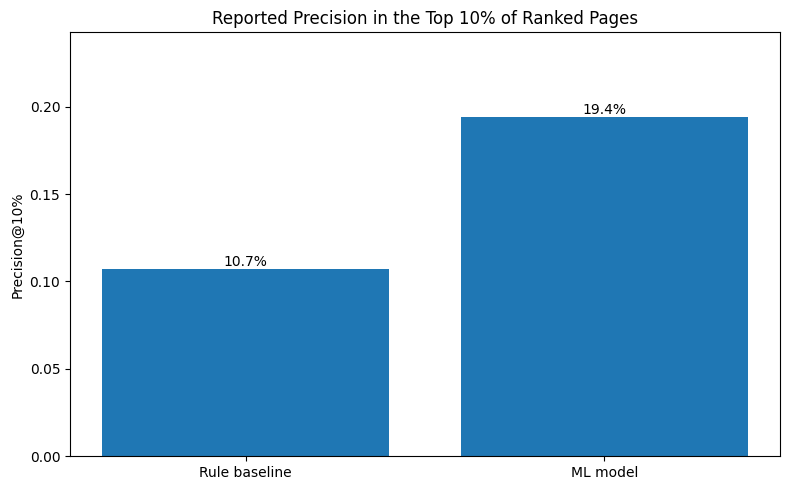

Rule baseline: 10.7%
ML model:      19.4%
Absolute improvement: 8.7 percentage points
Relative improvement: 81.3%


In [24]:

# Section 4: Compare the reported model results

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

results_path = "/content/artifacts/results_table.csv"
results = pd.read_csv(results_path)

# Display the complete comparison table
display(results)

# Plot Precision@10% for both methods
plt.figure(figsize=(8, 5))
plt.bar(results["method"], results["Precision@10%"])
plt.ylabel("Precision@10%")
plt.title("Reported Precision in the Top 10% of Ranked Pages")
plt.ylim(0, max(results["Precision@10%"]) * 1.25)

for i, value in enumerate(results["Precision@10%"]):
    plt.text(i, value, f"{value:.1%}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

# Calculate the difference using the reported values
baseline = results.loc[
    results["method"] == "Rule baseline", "Precision@10%"
].iloc[0]

ml_model = results.loc[
    results["method"] == "ML model", "Precision@10%"
].iloc[0]

print(f"Rule baseline: {baseline:.1%}")
print(f"ML model:      {ml_model:.1%}")
print(f"Absolute improvement: {(ml_model - baseline) * 100:.1f} percentage points")
print(
    f"Relative improvement: "
    f"{((ml_model - baseline) / baseline) * 100:.1f}%"
)


## 5. Limitations

*What this work cannot claim.*

In [ ]:
limitations = [
 "Numbers here come from SYNTHETIC stand-in data. They show the method works, not how it performs on real pages.",
 "Labels are reviewer decisions, so the model learns reviewer habits, not ground-truth harm.",
 "Single time split: results may shift in other periods (concept drift, seasonality).",
 "Cost per review ($2.00) is an assumption, not a measured figure.",
 "Pages are scored independently; no site-level or network effects are modelled.",
 "Offline evaluation only: no live A/B test, so no causal claim about workflow impact.",
 "Directional, decision-support evidence. Not proof that the model should fully replace human judgment.",
]
for i, t in enumerate(limitations, 1): print(f"{i}. {t}")

1. Numbers here come from SYNTHETIC stand-in data. They show the method works, not how it performs on real pages.
2. Labels are reviewer decisions, so the model learns reviewer habits, not ground-truth harm.
3. Single time split: results may shift in other periods (concept drift, seasonality).
4. Cost per review ($2.00) is an assumption, not a measured figure.
5. Pages are scored independently; no site-level or network effects are modelled.
6. Offline evaluation only: no live A/B test, so no causal claim about workflow impact.
7. Directional, decision-support evidence. Not proof that the model should fully replace human judgment.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [ ]:
m, b = res.loc["ML model"], res.loc["Rule baseline"]
recs = pd.DataFrame([
 [1, "Pilot model-driven prioritization on a small share of the review queue (shadow mode first)",
     f"Precision@10% {m.iloc[2]:.1%} vs {b.iloc[2]:.1%} for rules", "Medium", "Run 4-week shadow test on real labels"],
 [2, "Keep the rule baseline as a fallback and sanity check",
     "Rules are transparent and cheap; model can fail silently on drift", "High", "Alert if model/rule agreement drops"],
 [3, "Set the review budget by cost, not by habit",
     f"Cost per high-risk page ${m["Cost per high-risk page ($)"]:.2f} vs ${b["Cost per high-risk page ($)"]:.2f} (assumed $2/review)", "Low", "Replace the $2 assumption with real cost"],
 [4, "Retrain on a schedule and monitor precision by month",
     "Time-split design shows drift is the main risk", "Medium", "Monthly retrain + dashboard"],
 [5, "Audit top-scored false positives with reviewers",
     "Finds label bias and missing features", "Medium", "Sample 100 per month"],
], columns=["Rank","Action","Evidence (observed)","Confidence","Next step"])
recs.to_csv("artifacts/recommendations.csv", index=False)
display(recs)

,Rank,Action,Evidence (observed),Confidence,Next step
0,1,Pilot model-driven prioritization on a small s...,Precision@10% 19.4% vs 10.7% for rules,Medium,Run 4-week shadow test on real labels
1,2,Keep the rule baseline as a fallback and sanit...,Rules are transparent and cheap; model can fai...,High,Alert if model/rule agreement drops
2,3,"Set the review budget by cost, not by habit",Cost per high-risk page $10.31 vs $18.69 (assu...,Low,Replace the $2 assumption with real cost
3,4,Retrain on a schedule and monitor precision by...,Time-split design shows drift is the main risk,Medium,Monthly retrain + dashboard
4,5,Audit top-scored false positives with reviewers,Finds label bias and missing features,Medium,Sample 100 per month


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

In [25]:

# Inspect available project artifacts and their contents

import os

for folder in ["/content/artifacts", "/content"]:
    print(f"\nFiles in {folder}:")
    if os.path.exists(folder):
        for item in os.listdir(folder):
            path = os.path.join(folder, item)
            if os.path.isfile(path):
                print(f"  {item} ({os.path.getsize(path)} bytes)")
            elif folder == "/content/artifacts":
                print(f"  {item}/")

print("\nSearching for notebooks and model/data files...")
extensions = (".ipynb", ".py", ".csv", ".parquet", ".json", ".pkl", ".joblib")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [
        d for d in dirs
        if d not in {".git", ".cache", "node_modules"}
    ]

    for file in files:
        if file.lower().endswith(extensions):
            print(os.path.join(root, file))



Files in /content/artifacts:
  results_table.csv (176 bytes)
  recommendations.csv (800 bytes)
  precision_at_budget.png (40037 bytes)
  feature_importance.png (39017 bytes)
  recall_curve.png (67950 bytes)

Files in /content:

Searching for notebooks and model/data files...
/content/.config/.last_update_check.json
/content/artifacts/results_table.csv
/content/artifacts/recommendations.csv
/content/sample_data/anscombe.json
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [26]:

# Load the complete public FlyRank repository into Colab

import os
import subprocess

repo_url = (
    "https://github.com/"
    "ayazahmedbscsf23-art/flyrank-ml-internship.git"
)
repo_dir = "/content/flyrank-ml-internship"

if not os.path.isdir(os.path.join(repo_dir, ".git")):
    result = subprocess.run(
        ["git", "clone", repo_url, repo_dir],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        print("Repository clone failed:")
        print(result.stderr)
    else:
        print("Repository cloned successfully.")
else:
    print("Repository already exists in this runtime.")

# Inspect the dataset and pipeline files
paths_to_check = [
    "data/raw/content_refresh_anonymized.csv",
    "scripts/run_all.py",
    "scripts/01_prepare_features.py",
    "scripts/02_baseline_score.py",
    "scripts/03_train_model.py",
    "scripts/04_evaluate_and_export.py",
    "scripts/05_build_pdf_report.py",
    "requirements.txt",
]

print("\nChecking project files:")

for relative_path in paths_to_check:
    full_path = os.path.join(repo_dir, relative_path)
    print(
        f"{'FOUND' if os.path.exists(full_path) else 'NOT FOUND'}: "
        f"{relative_path}"
    )


Repository cloned successfully.

Checking project files:
FOUND: data/raw/content_refresh_anonymized.csv
FOUND: scripts/run_all.py
FOUND: scripts/01_prepare_features.py
FOUND: scripts/02_baseline_score.py
FOUND: scripts/03_train_model.py
FOUND: scripts/04_evaluate_and_export.py
FOUND: scripts/05_build_pdf_report.py
FOUND: requirements.txt


In [27]:

# Step 11: Inspect the real dataset and analysis pipeline

import os
import pandas as pd

repo_dir = "/content/flyrank-ml-internship"
dataset_path = os.path.join(
    repo_dir, "data/raw/content_refresh_anonymized.csv"
)

# 1. Inspect the dataset
print("=" * 60)
print("DATASET INSPECTION")
print("=" * 60)

df = pd.read_csv(dataset_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
for col in df.columns:
    print("-", col)

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isna().sum())

# 2. Inspect how the pipeline runs
print("\n" + "=" * 60)
print("PIPELINE ENTRY POINT")
print("=" * 60)

run_file = os.path.join(repo_dir, "scripts/run_all.py")

with open(run_file, "r", encoding="utf-8") as f:
    print(f.read())

# 3. Inspect dependencies
print("\n" + "=" * 60)
print("REQUIREMENTS")
print("=" * 60)

requirements_file = os.path.join(repo_dir, "requirements.txt")

with open(requirements_file, "r", encoding="utf-8") as f:
    print(f.read())


DATASET INSPECTION
Dataset shape: (30000, 44)

Column names:
- content_id
- client_id
- search_volume
- competition
- competition_level
- cpc
- content_type
- main_intent
- word_count
- char_count
- provider_used
- model_used
- impressions_90d
- clicks_90d
- pageviews_90d
- sessions_90d
- users_90d
- engaged_sessions_90d
- ai_sessions_90d
- scroll_events_90d
- days_with_impressions
- days_with_sessions
- impressions_last_30d
- clicks_last_30d
- sessions_last_30d
- impressions_prev_30d
- clicks_prev_30d
- sessions_prev_30d
- content_age_days
- age_tier
- age_tier_order
- days_since_last_update
- freshness_tier
- word_count_tier
- char_count_tier
- ctr
- avg_position
- engagement_rate
- scroll_rate
- ai_traffic_pct
- impression_tier
- position_tier
- trend_direction
- trend_pct

First five rows:


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7



Data types:
content_id                 object
client_id                  object
search_volume             float64
competition               float64
competition_level          object
cpc                       float64
content_type               object
main_intent                object
word_count                float64
char_count                float64
provider_used              object
model_used                 object
impressions_90d             int64
clicks_90d                  int64
pageviews_90d               int64
sessions_90d                int64
users_90d                   int64
engaged_sessions_90d        int64
ai_sessions_90d             int64
scroll_events_90d           int64
days_with_impressions       int64
days_with_sessions          int64
impressions_last_30d        int64
clicks_last_30d             int64
sessions_last_30d           int64
impressions_prev_30d        int64
clicks_prev_30d             int64
sessions_prev_30d           int64
content_age_days            int64
a

In [28]:

# Step 12: Inspect target, features, training, and evaluation

from pathlib import Path

repo_dir = Path("/content/flyrank-ml-internship")

scripts_to_inspect = [
    "scripts/01_prepare_features.py",
    "scripts/02_baseline_score.py",
    "scripts/03_train_model.py",
    "scripts/04_evaluate_and_export.py",
]

for relative_path in scripts_to_inspect:
    path = repo_dir / relative_path

    print("\n" + "=" * 75)
    print(f"SCRIPT: {relative_path}")
    print("=" * 75)

    if path.exists():
        content = path.read_text(encoding="utf-8")
        print(content[:14000])

        if len(content) > 14000:
            print("\n[Output shortened; remaining content not shown.]")
    else:
        print("Script not found.")



SCRIPT: scripts/01_prepare_features.py
from __future__ import annotations

import argparse
from pathlib import Path

import numpy as np
import pandas as pd

from ml_utils import (
    BOOLEAN_COLUMNS,
    CATEGORICAL_COLUMNS,
    MODEL_CATEGORICAL_FEATURES,
    MODEL_NUMERIC_FEATURES,
    NUMERIC_COLUMNS,
    PROCESSED_DIR,
    RAW_PATH,
    display_path,
    ensure_dirs,
    to_bool_series,
    write_json,
)


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Prepare FlyRank refresh feature vector.")
    parser.add_argument("--input", default=str(RAW_PATH), help="Raw anonymized CSV export.")
    parser.add_argument(
        "--output",
        default=str(PROCESSED_DIR / "refresh_feature_vector.csv"),
        help="Prepared feature-vector CSV.",
    )
    return parser.parse_args()


def main() -> None:
    args = parse_args()
    ensure_dirs()

    input_path = Path(args.input)
    if not input_path.exists():
        raise FileNotFoundError(
 

In [29]:

from pathlib import Path

repo_dir = Path("/content/flyrank-ml-internship")

files_to_check = [
    "scripts/01_prepare_features.py",
    "scripts/03_train_model.py",
]

for relative_path in files_to_check:
    path = repo_dir / relative_path
    content = path.read_text(encoding="utf-8")

    print("\n" + "=" * 60)
    print(relative_path)
    print("=" * 60)

    for line_number, line in enumerate(content.splitlines(), start=1):
        if any(term in line.lower() for term in [
            "target", "label", "feature", "drop(", "train_test_split",
            "group", "client_id", "predict(", "fit(", "is_declining_label",
            "suggested_action", "final_reason_codes"
        ]):
            print(f"{line_number}: {line}")



scripts/01_prepare_features.py
12:     MODEL_CATEGORICAL_FEATURES,
13:     MODEL_NUMERIC_FEATURES,
25:     parser = argparse.ArgumentParser(description="Prepare FlyRank refresh feature vector.")
29:         default=str(PROCESSED_DIR / "refresh_feature_vector.csv"),
30:         help="Prepared feature-vector CSV.",
49:     required = ["content_id", "client_id", "impressions_90d", "sessions_90d", "content_age_days", "trend_direction"]
110:     df["is_declining_label"] = df["trend_direction"].str.lower().eq("down").astype(int)
131:         "declining_rows": int(df["is_declining_label"].sum()),
132:         "declining_rate": float(df["is_declining_label"].mean()) if len(df) else 0.0,
133:         "model_numeric_features": MODEL_NUMERIC_FEATURES,
134:         "model_categorical_features": MODEL_CATEGORICAL_FEATURES,
135:         "target_definition": "trend_direction == 'down'",
137:     write_json(PROCESSED_DIR / "feature_metadata.json", metadata)

scripts/03_train_model.py
18: from sklearn

## Acknowledgments & Data Credit

I would like to thank the FlyRank team and internship mentors for providing the learning resources, project guidance, and research materials that supported this capstone project.

**Data Credit:** This project uses the data and code made available through the provided FlyRank internship repository and its associated materials. The dataset, its original source, and any applicable usage conditions should be credited according to the repository documentation.

**Research Credit:** The research paper discussed during the internship is acknowledged as a reference for understanding model evaluation, validation methodology, and responsible interpretation of machine learning results. Its full title, authors, and publication details should be included in the references section.

**Tools and Assistance:** GitHub, Jupyter Notebook, and the machine learning libraries actually used in this project supported implementation and evaluation. AI assistance was used to help understand concepts and improve documentation where applicable.

All results and conclusions are based on the experiments performed in this project. The findings should be interpreted within the limitations of the available data and evaluation design.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
